<a href="https://colab.research.google.com/github/WalterPerjenko/LabWork_Statistic/blob/main/%D0%9B%D0%B0%D0%B1%D0%B0_%D1%81%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D0%BA%D0%B0_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import io
import json
import hashlib
import zipfile
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from IPython.display import display, Markdown


# 1. НАСТРОЙКИ И ЗАГРУЗКА ДАННЫХ

SEED = 42

# признаки (Даша)
FEATURES = ["LogS", "MolWt"]

# все признаки
ALL_FEATURES = ["LogS", "MolWt", "MolLogP"]

URL = (
    "https://raw.githubusercontent.com/"
    "mcsorkun/AqSolDB/master/results/data_curated.csv"
)

OUT = Path("aqsoldb_results")
OUT.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", font="DejaVu Sans")

with urlopen(URL, timeout=60) as response:
    source_bytes = response.read()

raw = pd.read_csv(io.BytesIO(source_bytes))

# сохранение исходных данныз
(OUT / "aqsoldb_raw.csv").write_bytes(source_bytes)

(OUT / "source.json").write_text(
    json.dumps(
        {
            "url": URL,
            "sha256": hashlib.sha256(source_bytes).hexdigest(),
            "seed": SEED,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Исходный размер:", raw.shape)
display(raw.head())

display(
    pd.DataFrame(
        {
            "Тип": raw.dtypes.astype(str),
            "Пропусков": raw.isna().sum(), # количество отсутствующих значений в столбце.
        }
    )
)



Исходный размер: (9982, 26)


,ID,Name,InChI,InChIKey,SMILES,Solubility,SD,Occurrences,Group,MolWt,...,NumRotatableBonds,NumValenceElectrons,NumAromaticRings,NumSaturatedRings,NumAliphaticRings,RingCount,TPSA,LabuteASA,BalabanJ,BertzCT
0,A-3,"N,N,N-trimethyloctadecan-1-aminium bromide",InChI=1S/C21H46N.BrH/c1-5-6-7-8-9-10-11-12-13-...,SZEMGTQCPRNXEG-UHFFFAOYSA-M,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616127,0.0,1,G1,392.510,...,17.0,142.0,0.0,0.0,0.0,0.0,0.00,158.520601,0.000000e+00,210.377334
1,A-4,Benzo[cd]indol-2(1H)-one,InChI=1S/C11H7NO/c13-11-8-5-1-3-7-4-2-6-9(12-1...,GPYLCFQEKPUWLD-UHFFFAOYSA-N,O=C1Nc2cccc3cccc1c23,-3.254767,0.0,1,G1,169.183,...,0.0,62.0,2.0,0.0,1.0,3.0,29.10,75.183563,2.582996e+00,511.229248
2,A-5,4-chlorobenzaldehyde,InChI=1S/C7H5ClO/c8-7-3-1-6(5-9)2-4-7/h1-5H,AVPYQKSLYISFPO-UHFFFAOYSA-N,Clc1ccc(C=O)cc1,-2.177078,0.0,1,G1,140.569,...,1.0,46.0,1.0,0.0,0.0,1.0,17.07,58.261134,3.009782e+00,202.661065
3,A-8,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",InChI=1S/2C23H22O3.Zn/c2*1-15(17-9-5-3-6-10-17...,XTUPUYCJWKHGSW-UHFFFAOYSA-L,[Zn++].CC(c1ccccc1)c2cc(C(C)c3ccccc3)c(O)c(c2)...,-3.924409,0.0,1,G1,756.226,...,10.0,264.0,6.0,0.0,0.0,6.0,120.72,323.755434,2.322963e-07,1964.648666
4,A-9,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,InChI=1S/C25H30N2O4/c1-5-20(26(10-22-14-28-22)...,FAUAZXVRLVIARB-UHFFFAOYSA-N,C1OC1CN(CC2CO2)c3ccc(Cc4ccc(cc4)N(CC5CO5)CC6CO...,-4.662065,0.0,1,G1,422.525,...,12.0,164.0,2.0,4.0,4.0,6.0,56.60,183.183268,1.084427e+00,769.899934


,Тип,Пропусков
ID,object,0
Name,object,0
InChI,object,0
InChIKey,object,0
SMILES,object,0
Solubility,float64,0
SD,float64,0
Occurrences,int64,0
Group,object,0
MolWt,float64,0


In [ ]:


# 2. ОЧИСТКА ОБЩЕЙ ТАБЛИЦЫ


# переименование , повторный логарифм не берётся.
data = raw.rename(columns={"Solubility": "LogS"}).copy()

duplicate_count = int(data.duplicated().sum())
data = data.drop_duplicates().copy()

# к числовуму типу
for c in ALL_FEATURES:
    data[c] = pd.to_numeric(data[c], errors="coerce")

display(
    pd.DataFrame(
        {
            "Пропуски / нечисловые": data[ALL_FEATURES].isna().sum(),
            "Бесконечности": np.isinf(data[ALL_FEATURES]).sum(),
        }
    )
)

# положительная молярная
valid = (
    np.isfinite(data[ALL_FEATURES]).all(axis=1)
    & (data["MolWt"] > 0)
)

invalid_count = int((~valid).sum())
data = data.loc[valid].reset_index(drop=True)

# проверка повторов  по InChIKey (если отдельные числовые свойства совпадают то это не дубликат)
keys = data["InChIKey"].astype("string").str.strip()

repeated = (
    keys.notna()
    & keys.ne("")
    & keys.duplicated(keep=False)
)

if repeated.any():
    display(data.loc[repeated, ["InChIKey"] + ALL_FEATURES])
    raise ValueError(
        "Повторные соединения: требуется проверить InChIKey."
    )

N = len(data)

if N < 10 or (data[FEATURES].nunique() < 2).any():
    raise ValueError(
        "Недостаточно корректных неодинаковых наблюдений."
    )

data.to_csv(OUT / "aqsoldb_clean.csv", index=False)

print(
    f"Полных повторов: {duplicate_count}; "
    f"некорректных строк: {invalid_count}; "
    f"N = {N}."
)

display(
    Markdown(
        r"""
**Случайный эксперимент:** равновероятно выбрать соединение
из очищенной базы.

LogS = log₁₀(S / (1 моль/л)),  S растворимость
MolWt = молярная масса, г/моль
MolLogP =  рассчитанный логарифм коэффициента распределения октанол/вода
каждая строка имее вероятность 1/N.
генеральная совокупность данного исследования = очищенный AqSolDB.

"""
    )
)

,Пропуски / нечисловые,Бесконечности
LogS,0,0
MolWt,0,0
MolLogP,0,0


Полных повторов: 0; некорректных строк: 0; N = 9982.



**Случайный эксперимент:** равновероятно выбрать соединение
из очищенной базы.

LogS = log₁₀(S / (1 моль/л)),  S растворимость
MolWt = молярная масса, г/моль
MolLogP =  рассчитанный логарифм коэффициента распределения октанол/вода
каждая строка имее вероятность 1/N.
генеральная совокупность данного исследования = очищенный AqSolDB.



In [ ]:
# 3. ОПИСАТЕЛЬНЫЕ СТАТИСТИКИ LogS И MolWt

population = data[FEATURES]

# ген среднее
mu = population.mean()

# ген дисперсия: делитель N
variance = population.var(ddof=0)

# ген стандартное отклонение
sigma = np.sqrt(variance)

summary = pd.DataFrame({
    "N": population.count(),
    "Среднее": mu,
    "Медиана": population.median(),
    "Дисперсия (N)": variance,
    "Стандартное отклонение": sigma,
    "Минимум": population.min(),
    "Q1": population.quantile(0.25),
    "Q3": population.quantile(0.75),
    "Максимум": population.max(),
    "Асимметрия": [
        skew(population[c], bias=True)
        for c in FEATURES
    ],
    "Эксцесс": [
        kurtosis(population[c], fisher=True, bias=True)
        for c in FEATURES
    ],
})

display(summary.round(5))

summary.to_csv(OUT / "population_statistics.csv")

,N,Среднее,Медиана,Дисперсия (N),Стандартное отклонение,Минимум,Q1,Q3,Максимум,Асимметрия,Эксцесс
LogS,9982,-2.88991,-2.61817,5.60759,2.36804,-13.1719,-4.32633,-1.20973,2.13768,-0.55161,-0.0600
MolWt,9982,266.66595,228.68200,33918.51441,184.16980,9.0120,162.27600,320.43600,5299.45600,5.49376,80.9231


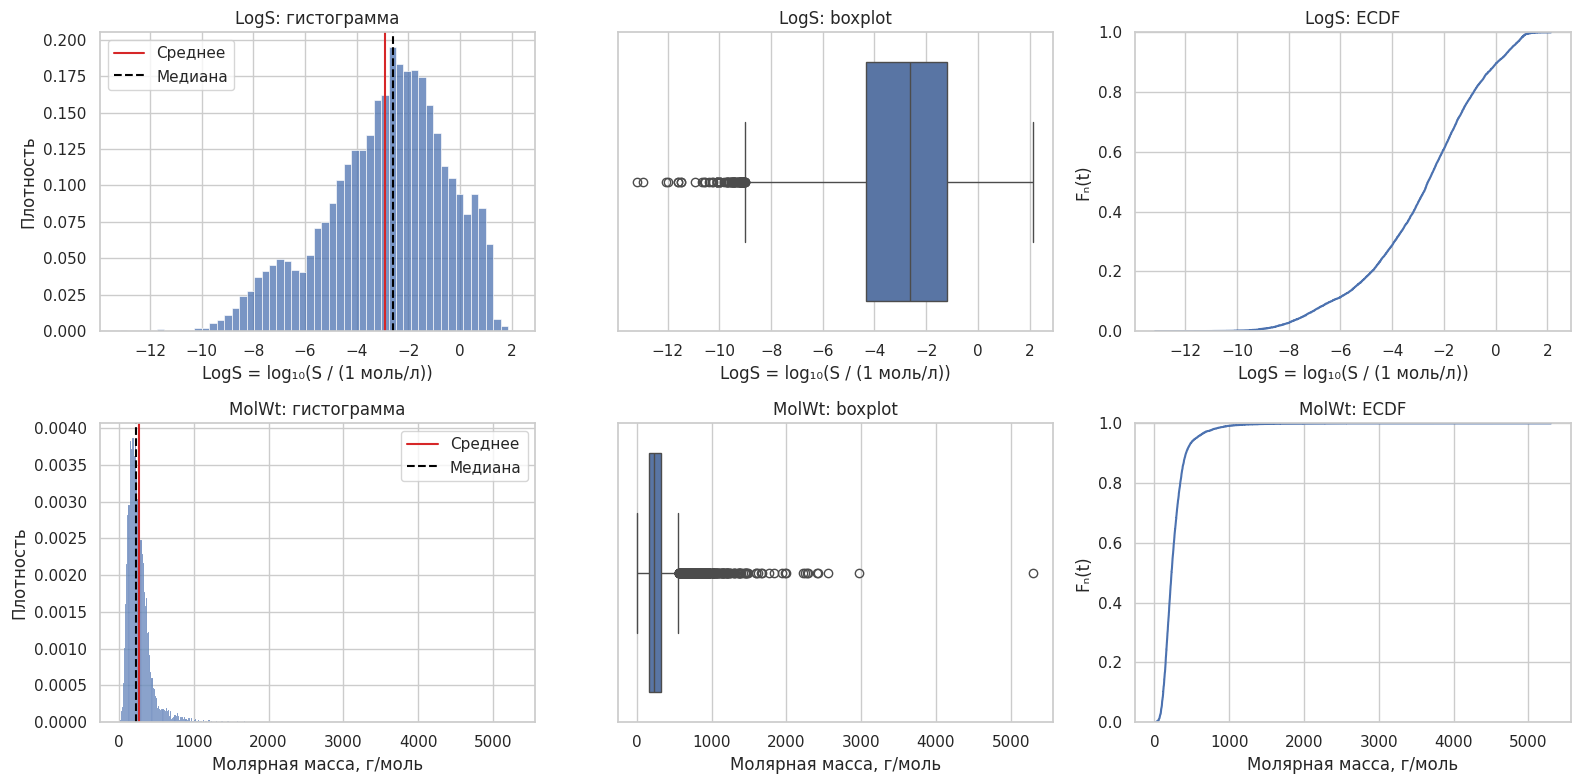

,Нижняя граница,Верхняя граница,Отмечено,"Доля, %"
Признак,,,,
LogS,-9.0012,3.4652,82,0.8215
MolWt,-74.9640,557.6760,488,4.8888


In [ ]:
# 4. РАСПРЕДЕЛЕНИЯ И КРАЙНИЕ НАБЛЮДЕНИЯ

labels = {
    "LogS": "LogS = log₁₀(S / (1 моль/л))",
    "MolWt": "Молярная масса, г/моль",
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
outlier_rows = []

for row, c in enumerate(FEATURES):
    x = data[c]

    # границы по правилу межквартильного размаха
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = (x < lower) | (x > upper)

    outlier_rows.append({
        "Признак": c,
        "Нижняя граница": lower,
        "Верхняя граница": upper,
        "Отмечено": int(flagged.sum()),
        "Доля, %": 100 * flagged.mean(),
    })

    # гстограмма
    sns.histplot(
        x=x, bins="fd", stat="density", ax=axes[row, 0]
    )
    axes[row, 0].axvline(
        mu[c], color="tab:red", label="Среднее"
    )
    axes[row, 0].axvline(
        x.median(), color="black",
        linestyle="--", label="Медиана"
    )
    axes[row, 0].set(
        xlabel=labels[c],
        ylabel="Плотность",
        title=f"{c}: гистограмма",
    )
    axes[row, 0].legend()

    # боксплот
    sns.boxplot(x=x, ax=axes[row, 1])
    axes[row, 1].set(
        xlabel=labels[c],
        title=f"{c}: boxplot",
    )

    # Эмпирическая функция распределения
    sns.ecdfplot(x=x, ax=axes[row, 2])
    axes[row, 2].set(
        xlabel=labels[c],
        ylabel="Fₙ(t)",
        title=f"{c}: ECDF",
    )

plt.tight_layout()
plt.savefig(
    OUT / "01_distributions.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

outliers = pd.DataFrame(outlier_rows).set_index("Признак")

display(outliers.round(4))
outliers.to_csv(OUT / "iqr_flags.csv")


,Среднее,Стандартное отклонение (N),Минимум,Максимум
LogS_z,-0.000000,1.000000,-4.341991,2.123106
MolWt_z,-0.000000,1.000000,-1.399002,27.326902
LogS_minmax,0.671605,0.154677,0.000000,1.000000
MolWt_minmax,0.048702,0.034812,0.000000,1.000000


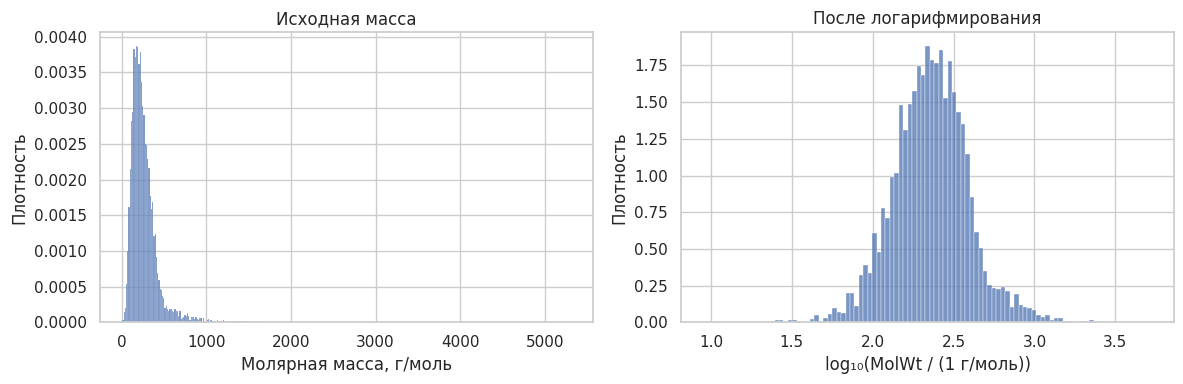

Асимметрия MolWt до и после логарифмирования: 5.494 0.045


In [ ]:

# 5. СТАНДАРТИЗАЦИЯ И НОРМАЛИЗАЦИЯ


# насклько значение отклняется от среднего z = (x - среднее) / стандартное отклонение.
# в диапазон. 0-1 u = (x - минимум) / (максимум - минимум).

scaled = data.copy()
parameters = {}

for c in FEATURES:
    low = data[c].min()
    high = data[c].max()

    scaled[c + "_z"] = (data[c] - mu[c]) / sigma[c]
    scaled[c + "_minmax"] = (data[c] - low) / (high - low)

    parameters[c] = {
        "mean": float(mu[c]),
        "std_ddof0": float(sigma[c]),
        "min": float(low),
        "max": float(high),
    }

#  log10(MolWt / (1 г/моль)).
scaled["MolWt_log10"] = np.log10(data["MolWt"])

cols = [
    "LogS_z",
    "MolWt_z",
    "LogS_minmax",
    "MolWt_minmax",
]

display(
    pd.DataFrame(
        {
            "Среднее": scaled[cols].mean(),
            "Стандартное отклонение (N)": scaled[cols].std(ddof=0),
            "Минимум": scaled[cols].min(),
            "Максимум": scaled[cols].max(),
        }
    ).round(6)
)

scaled.to_csv(OUT / "aqsoldb_scaled.csv", index=False)

(OUT / "scaling_parameters.json").write_text(
    json.dumps(parameters, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    x=data["MolWt"],
    bins="fd",
    stat="density",
    ax=axes[0],
)

axes[0].set(
    xlabel=labels["MolWt"],
    ylabel="Плотность",
    title="Исходная масса",
)

sns.histplot(
    x=scaled["MolWt_log10"],
    bins="fd",
    stat="density",
    ax=axes[1],
)

axes[1].set(
    xlabel="log₁₀(MolWt / (1 г/моль))",
    ylabel="Плотность",
    title="После логарифмирования",
)

plt.tight_layout()
plt.savefig(
    OUT / "02_mass_transform.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print(
    "Асимметрия MolWt до и после логарифмирования:",
    round(float(skew(data["MolWt"])), 3),
    round(float(skew(scaled["MolWt_log10"])), 3),
)

In [ ]:


# 6. ГЕНЕРАЛЬНЫЕ И ВЫБОРОЧНЫЕ ХАРАКТЕРИСТИКИ




rng = np.random.default_rng(SEED)
n_sample = min(500, N)

comparison_rows = []

for replace, method, suffix in [
    (True, "С возвращением", "with"), #могут повторяться
    (False, "Без возвращения", "without"), #ровн 500
]:
    indices = rng.choice(N, size=n_sample, replace=replace)
    sample = data.iloc[indices].copy()

    sample.to_csv(
        OUT / f"sample_{suffix}.csv",
        index=False,
    )

    for c in FEATURES:
        mean_hat = sample[c].mean()
        var_hat = sample[c].var(ddof=1)

        if not replace:
            var_hat *= (N - 1) / N

        # Поправка на конечную совокупность
        fpc = (
            1.0
            if replace
            else (N - n_sample) / (N - 1)
        )

        comparison_rows.append(
            {
                "Отбор": method,
                "Признак": c,
                "n": n_sample,
                "Среднее базы": mu[c],
                "Среднее выборки": mean_hat,
                "Абс. ошибка среднего": abs(mean_hat - mu[c]),
                "Дисперсия базы": variance[c],
                "Оценка дисперсии": var_hat,
                "Стандартная ошибка среднего": np.sqrt(
                    variance[c] / n_sample * fpc
                ),
                "Уникальных строк": len(np.unique(indices)),
            }
        )

comparison = pd.DataFrame(comparison_rows)

display(comparison.round(5))
comparison.to_csv(
    OUT / "sample_comparison.csv",
    index=False,
)



,Отбор,Признак,n,Среднее базы,Среднее выборки,Абс. ошибка среднего,Дисперсия базы,Оценка дисперсии,Стандартная ошибка среднего,Уникальных строк
0,С возвращением,LogS,500,-2.88991,-2.90723,0.01732,5.60759,5.27121,0.10590,486
1,С возвращением,MolWt,500,266.66595,273.80432,7.13837,33918.51441,34904.67127,8.23632,486
2,Без возвращения,LogS,500,-2.88991,-2.83455,0.05536,5.60759,5.38840,0.10322,500
3,Без возвращения,MolWt,500,266.66595,259.92170,6.74425,33918.51441,33878.92870,8.02780,500


,Отбор,Признак,n,RMSE среднего,RMSE среднего / σ,Теория RMSE среднего / σ,RMSE дисперсии,RMSE дисперсии / σ²,Доля |ошибки среднего| > 0.25σ
0,С возвращением,LogS,10,0.767461,0.324092,0.316228,2.518076,0.449048,0.430
1,С возвращением,MolWt,10,55.914088,0.303601,0.316228,77162.073847,2.274925,0.320
2,С возвращением,LogS,30,0.461011,0.194681,0.182574,1.380240,0.246138,0.225
3,С возвращением,MolWt,30,34.699120,0.188408,0.182574,26962.980898,0.794934,0.155
4,С возвращением,LogS,100,0.227377,0.096019,0.100000,0.778239,0.138783,0.010
5,С возвращением,MolWt,100,18.037851,0.097941,0.100000,25663.627336,0.756626,0.020
6,С возвращением,LogS,300,0.132581,0.055988,0.057735,0.466584,0.083206,0.000
7,С возвращением,MolWt,300,11.349510,0.061625,0.057735,16791.704243,0.495060,0.000
8,С возвращением,LogS,1000,0.072879,0.030776,0.031623,0.241067,0.042989,0.000
9,С возвращением,MolWt,1000,6.135600,0.033315,0.031623,10271.796698,0.302837,0.000


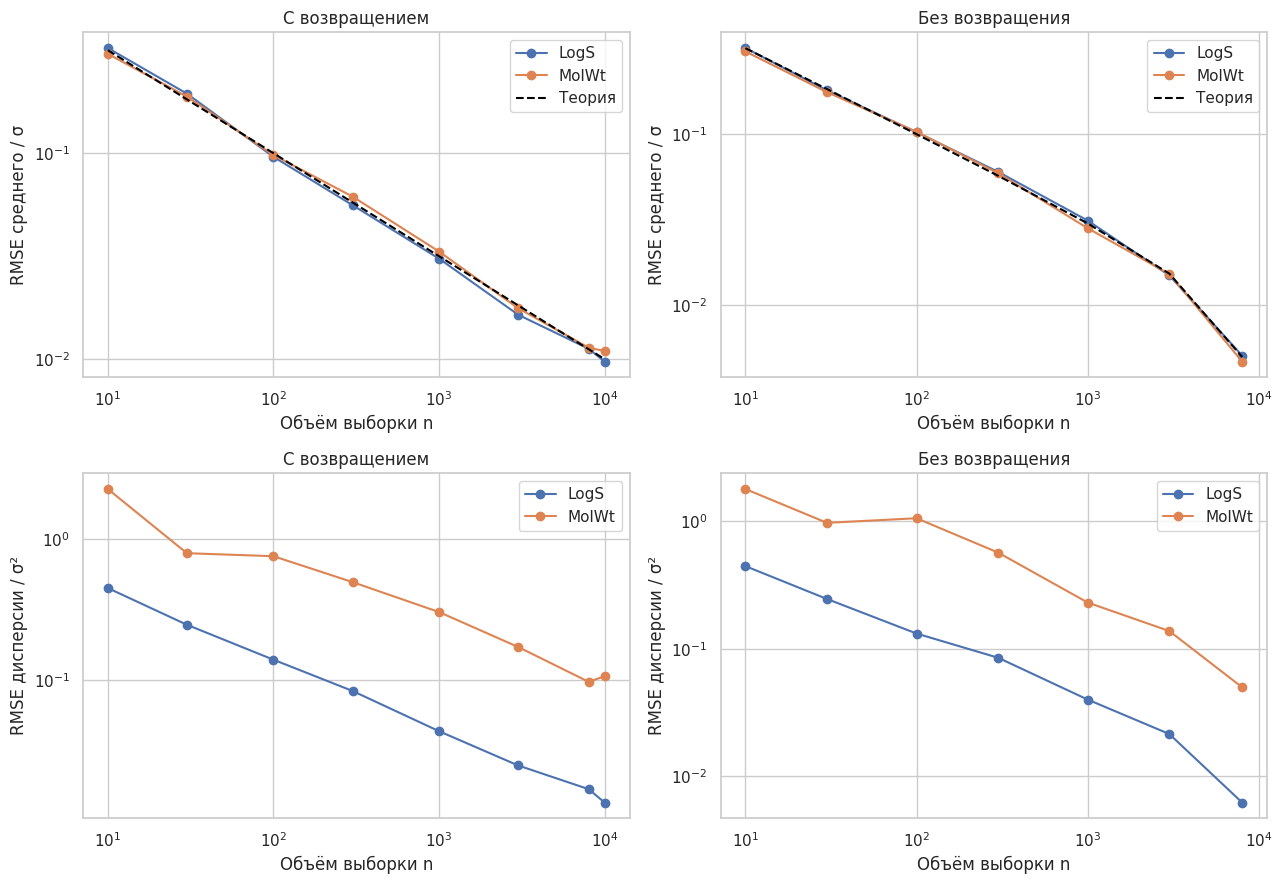

In [ ]:

# 7. СХОДИМОСТЬ ОЦЕНОК


# Для каждого объёма n выполняется 200 повторных отборов

B = 200

sizes = sorted(
    set(
        n
        for n in [10, 30, 100, 300, 1000, 3000, 8000, N]
        if 2 <= n <= N
    )
)

values = data[FEATURES].to_numpy(dtype=float)

true_mean = values.mean(axis=0)
true_var = values.var(axis=0, ddof=0)
true_std = np.sqrt(true_var)

rng_mc = np.random.default_rng(SEED + 1)
records = []

for replace, method in [
    (True, "С возвращением"),
    (False, "Без возвращения"),
]:
    for n in sizes:
        means = np.empty((B, len(FEATURES)))
        variances = np.empty_like(means)

        for b in range(B):
            indices = rng_mc.choice(
                N,
                size=n,
                replace=replace,
            )

            selected = values[indices]

            means[b] = selected.mean(axis=0)
            variances[b] = selected.var(axis=0, ddof=1)

        if not replace:
            variances *= (N - 1) / N

        mean_rmse = np.sqrt(
            ((means - true_mean) ** 2).mean(axis=0)
        )

        var_rmse = np.sqrt(
            ((variances - true_var) ** 2).mean(axis=0)
        )

        fpc = (
            1.0
            if replace
            else (N - n) / (N - 1)
        )

        for j, c in enumerate(FEATURES):
            records.append(
                {
                    "Отбор": method,
                    "Признак": c,
                    "n": n,
                    "RMSE среднего": mean_rmse[j],
                    "RMSE среднего / σ": (
                        mean_rmse[j] / true_std[j]
                    ),
                    "Теория RMSE среднего / σ": np.sqrt(fpc / n),
                    "RMSE дисперсии": var_rmse[j],
                    "RMSE дисперсии / σ²": (
                        var_rmse[j] / true_var[j]
                    ),
                    "Доля |ошибки среднего| > 0.25σ": float(
                        (
                            abs(means[:, j] - true_mean[j])
                            > 0.25 * true_std[j]
                        ).mean()
                    ),
                }
            )

convergence = pd.DataFrame(records)

display(convergence.round(6))
convergence.to_csv(
    OUT / "convergence.csv",
    index=False,
)


# графики сходимости
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for j, method in enumerate(
    ["С возвращением", "Без возвращения"]
):
    subset = convergence[
        convergence["Отбор"] == method
    ]

    #  n=N без возвращения ошибки близки к 0

    plotted = (
        subset
        if method == "С возвращением"
        else subset[subset["n"] < N]
    )

    for c in FEATURES:
        p = plotted[plotted["Признак"] == c]

        axes[0, j].loglog(
            p["n"],
            p["RMSE среднего / σ"],
            "o-",
            label=c,
        )

        axes[1, j].loglog(
            p["n"],
            p["RMSE дисперсии / σ²"],
            "o-",
            label=c,
        )

    theory = plotted[
        plotted["Признак"] == FEATURES[0]
    ]

    axes[0, j].loglog(
        theory["n"],
        theory["Теория RMSE среднего / σ"],
        "--",
        color="black",
        label="Теория",
    )

    for row, ylabel in [
        (0, "RMSE среднего / σ"),
        (1, "RMSE дисперсии / σ²"),
    ]:
        axes[row, j].set(
            xlabel="Объём выборки n",
            ylabel=ylabel,
            title=method,
        )

        axes[row, j].legend()

plt.tight_layout()
plt.savefig(
    OUT / "03_convergence.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)






In [ ]:

# 8. ВЫВОДЫ С РАССЧИТАННЫМИ ЧИСЛАМИ


conclusions = [
    (
        f"Генеральная совокупность исследования: "
        f"{N} соединений AqSolDB."
    ),
    (
        f"Полных повторов: {duplicate_count}; "
        f"некорректных строк: {invalid_count}."
    ),
]

for c in FEATURES:
    conclusions.append(
        f"{c}: среднее {mu[c]:.5f}; "
        f"медиана {data[c].median():.5f}; "
        f"дисперсия (делитель N) {variance[c]:.5f}; "
        f"асимметрия {summary.loc[c, 'Асимметрия']:.3f}; "
        f"по IQR отмечено "
        f"{int(outliers.loc[c, 'Отмечено'])} наблюдений, "
        f"они сохранены."
    )

    p = convergence[
        (convergence["Отбор"] == "С возвращением")
        & (convergence["Признак"] == c)
    ].sort_values("n")

    first = p.iloc[0]
    last = p.iloc[-1]

    conclusions.append(
        f"{c}: при n={int(first['n'])} "
        f"и n={int(last['n'])} "
        f"RMSE среднего/σ: "
        f"{first['RMSE среднего / σ']:.4f} и "
        f"{last['RMSE среднего / σ']:.4f}; "
        f"RMSE дисперсии/σ²: "
        f"{first['RMSE дисперсии / σ²']:.4f} и "
        f"{last['RMSE дисперсии / σ²']:.4f}."
    )


text = "\n\n".join(
    f"{i}. {t}"
    for i, t in enumerate(conclusions, 1)
)

display(Markdown(text))

(OUT / "conclusions.md").write_text(
    text,
    encoding="utf-8",
)


# сохранение


archive = Path("Lab01_AqSolDB_Daria_results.zip")

with zipfile.ZipFile(
    archive,
    "w",
    zipfile.ZIP_DEFLATED,
) as bundle:
    for item in sorted(OUT.iterdir()):
        if item.is_file():
            bundle.write(item, arcname=item.name)

print("Результаты сохранены в", archive)

try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(str(archive))

1. Генеральная совокупность исследования: 9982 соединений AqSolDB.

2. Полных повторов: 0; некорректных строк: 0.

3. LogS: среднее -2.88991; медиана -2.61817; дисперсия (делитель N) 5.60759; асимметрия -0.552; по IQR отмечено 82 наблюдений, они сохранены.

4. LogS: при n=10 и n=9982 RMSE среднего/σ: 0.3241 и 0.0097; RMSE дисперсии/σ²: 0.4490 и 0.0134.

5. MolWt: среднее 266.66595; медиана 228.68200; дисперсия (делитель N) 33918.51441; асимметрия 5.494; по IQR отмечено 488 наблюдений, они сохранены.

6. MolWt: при n=10 и n=9982 RMSE среднего/σ: 0.3036 и 0.0110; RMSE дисперсии/σ²: 2.2749 и 0.1061.

Результаты сохранены в Lab01_AqSolDB_Daria_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Размер генеральной совокупности по MolLogP: 9982


,N,Среднее,Медиана,Дисперсия (N),Стандартное отклонение,Минимум,Q1,Q3,Максимум,Асимметрия,Эксцесс
MolLogP,9982,1.97917,1.94922,12.37324,3.51756,-40.8732,0.61975,3.41903,68.54114,0.71824,29.50921


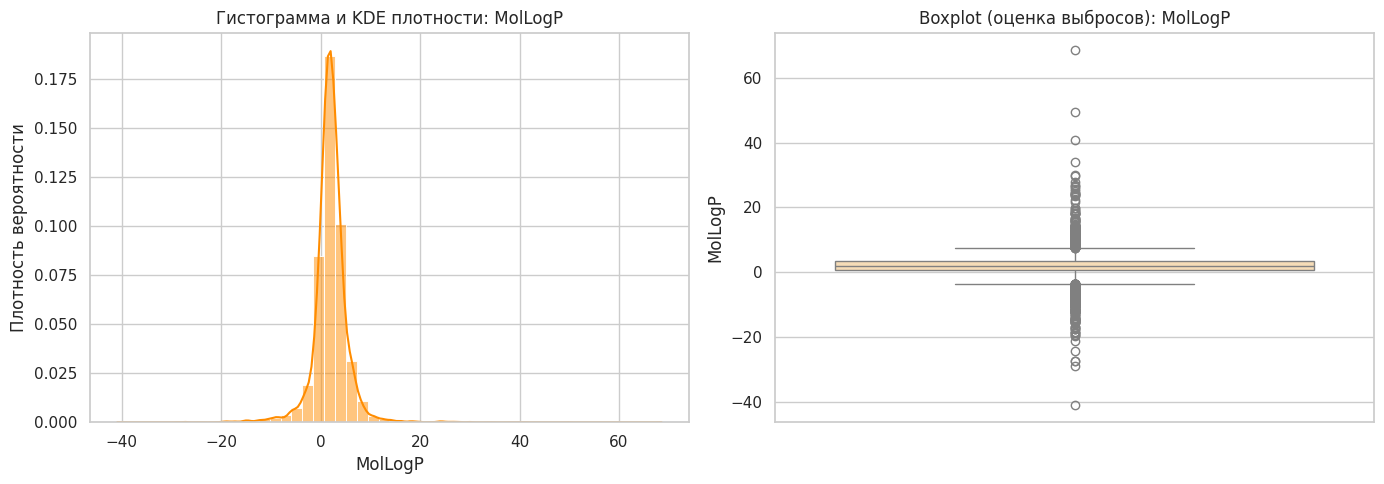

Сходимость выборочного среднего (с возвращением и без):
   N  Mean_without  Error_without  Mean_with  Error_with
  10      2.095880       0.116713   2.548472    0.569305
  50      1.673032       0.306135   1.548251    0.430916
 100      2.117833       0.138666   2.095764    0.116596
 500      1.907651       0.071516   1.708480    0.270688
1000      1.969194       0.009973   1.792947    0.186220
5000      1.941520       0.037647   1.970290    0.008877
Матрица корреляций Пирсона:
             MolLogP  Solubility     MolWt
MolLogP     1.000000   -0.608580  0.274489
Solubility -0.608580    1.000000 -0.368032
MolWt       0.274489   -0.368032  1.000000


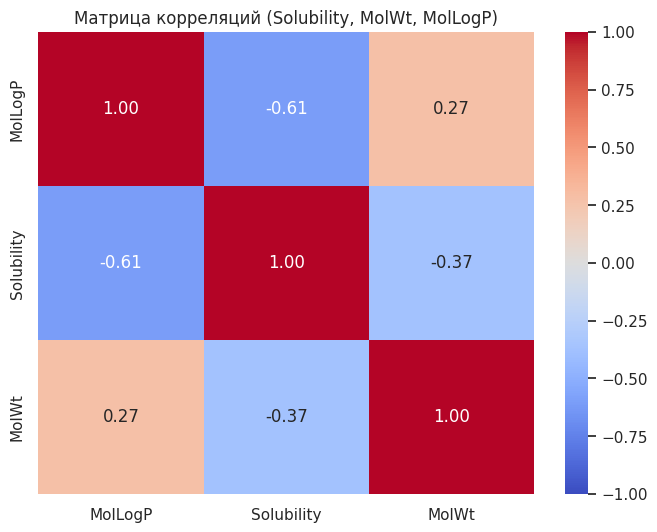


Статистическая гипотеза о связи Solubility и MolLogP:
Коэффициент корреляции: -0.6086, p-value: 0.0000e+00
Результат: Отвергаем H0. Между растворимостью и липофильностью есть статистически значимая связь.
Параметры нормального распределения: μ = 1.9792, σ = 3.5176


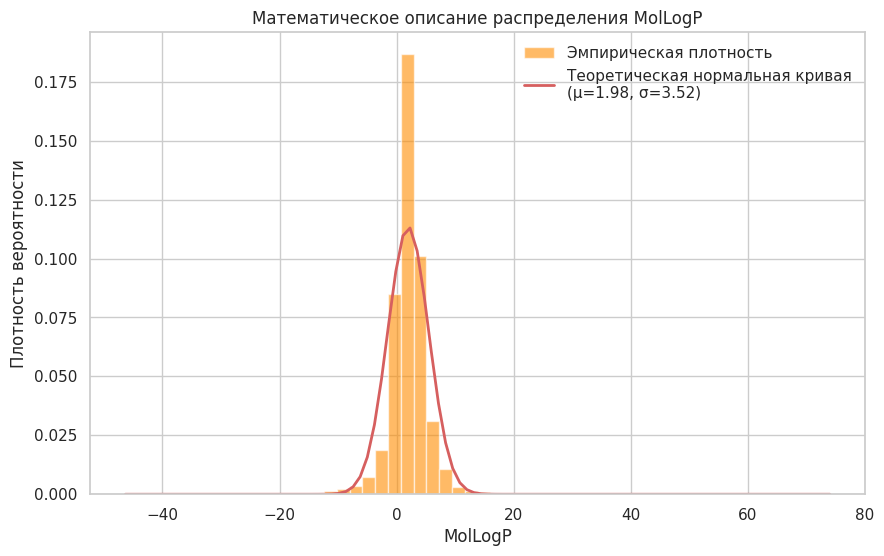

Матрица корреляций Пирсона


,MolLogP,Solubility,MolWt
MolLogP,1.0000,-0.6086,0.2745
Solubility,-0.6086,1.0000,-0.3680
MolWt,0.2745,-0.3680,1.0000



 Матрица корреляций Спирмана


,MolLogP,Solubility,MolWt
MolLogP,1.0000,-0.7398,0.4216
Solubility,-0.7398,1.0000,-0.5386
MolWt,0.4216,-0.5386,1.0000


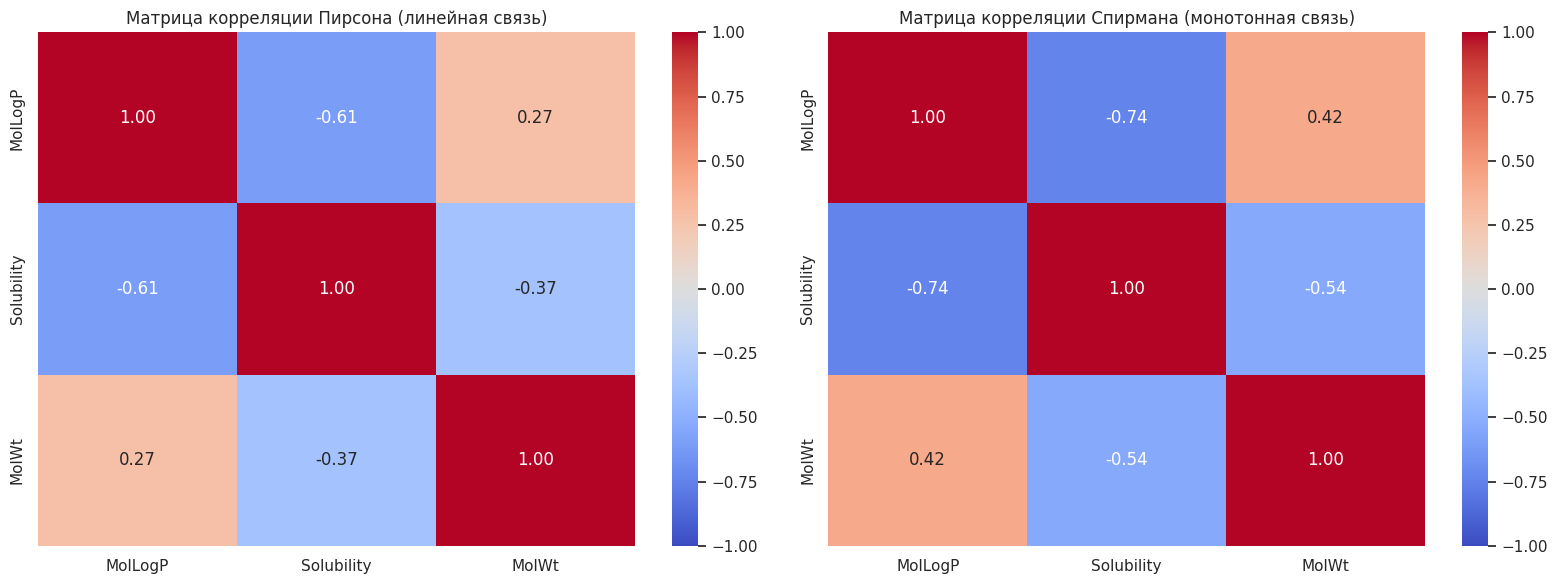

In [6]:
# Описание, EDA, распределение
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, skew
import scipy.stats as stats
import seaborn as sns

# Единая стилистика графиков для стандартов КТвД
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# Загрузка генеральной совокупности данных
url = 'https://raw.githubusercontent.com/whitead/dmol-book/main/data/curated-solubility-dataset.csv'
df = pd.read_csv(url)


features = ['MolLogP', 'Solubility', 'MolWt']
data = df[features].dropna().reset_index(drop=True)

population = data['MolLogP']
print(f'Размер генеральной совокупности по MolLogP: {population.count()}')

# Расчет основных статистик генеральной совокупности
mu = population.mean()
variance = population.var(ddof=0)  # Делитель N
sigma = np.sqrt(variance)

summary = pd.DataFrame(
    {
        'N': [population.count()],
        'Среднее': [mu],
        'Медиана': [population.median()],
        'Дисперсия (N)': [variance],
        'Стандартное отклонение': [sigma],
        'Минимум': [population.min()],
        'Q1': [population.quantile(0.25)],
        'Q3': [population.quantile(0.75)],
        'Максимум': [population.max()],
        'Асимметрия': [skew(population, bias=True)],
        'Эксцесс': [kurtosis(population, fisher=True, bias=True)],
    },
    index=['MolLogP'],
)

display(summary.round(5))

# Визуализация распределения MolLogP (гистограмма + KDE и Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    population,
    kde=True,
    ax=axes[0],
    color='darkorange',
    bins=50,
    stat='density',
)
axes[0].set_title('Гистограмма и KDE плотности: MolLogP')
axes[0].set_xlabel('MolLogP')
axes[0].set_ylabel('Плотность вероятности')

sns.boxplot(y=population, ax=axes[1], color='navajowhite')
axes[1].set_title('Boxplot (оценка выбросов): MolLogP')
axes[1].set_ylabel('MolLogP')

plt.tight_layout()
plt.show()

# Исследование сходимости выборочных оценок
sample_sizes = [10, 50, 100, 500, 1000, 5000]
est_results = []

np.random.seed(42)
for n in sample_sizes:
  s_without = population.sample(n=n, replace=False)
  s_with = population.sample(n=n, replace=True)

  est_results.append({
      'N': n,
      'Mean_without': s_without.mean(),
      'Error_without': abs(s_without.mean() - mu),
      'Mean_with': s_with.mean(),
      'Error_with': abs(s_with.mean() - mu),
  })

df_est = pd.DataFrame(est_results)
print('Сходимость выборочного среднего (с возвращением и без):')
print(df_est.to_string(index=False))



corr_matrix = data.corr(method='pearson')
print('Матрица корреляций Пирсона:')
print(corr_matrix)

# Тепловая карта связей
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Матрица корреляций (Solubility, MolWt, MolLogP)')
plt.show()


corr_val, p_value = stats.pearsonr(data['Solubility'], data['MolLogP'])
print(f'\nСтатистическая гипотеза о связи Solubility и MolLogP:')
print(f'Коэффициент корреляции: {corr_val:.4f}, p-value: {p_value:.4e}')

if p_value < 0.05:
  print(
      'Результат: Отвергаем H0. Между растворимостью и липофильностью есть'
      ' статистически значимая связь.'
  )
else:
  print('Результат: Нет оснований отвергнуть H0.')

fit_mu, fit_std = stats.norm.fit(population)
print(f'Параметры нормального распределения: μ = {fit_mu:.4f}, σ = {fit_std:.4f}')

# Графическое сравнение с нормальным законом
plt.figure(figsize=(10, 6))
count, bins, ignored = plt.hist(
    population,
    bins=50,
    density=True,
    alpha=0.6,
    color='darkorange',
    label='Эмпирическая плотность',
    )
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, fit_mu, fit_std)
plt.plot(
    x,
    p,
    'r-',
    linewidth=2,
    label=f'Теоретическая нормальная кривая\n(μ={fit_mu:.2f}, σ={fit_std:.2f})',
)

plt.title('Математическое описание распределения MolLogP')
plt.xlabel('MolLogP')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.show()

corr_pearson = data.corr(method='pearson')
corr_spearman = data.corr(method='spearman')

print('Матрица корреляций Пирсона')
display(corr_pearson.round(4))

print('\n Матрица корреляций Спирмана')
display(corr_spearman.round(4))

# Визуализация матриц корреляций
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    corr_pearson,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    ax=axes[0],
)
axes[0].set_title('Матрица корреляции Пирсона (линейная связь)')

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f',
    ax=axes[1],
)
axes[1].set_title('Матрица корреляции Спирмана (монотонная связь)')

plt.tight_layout()
plt.show()



